Irradiation Map Using Historical Baseline

In [4]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import xarray as xr

check input file exists below. Ensure to run cell above

In [18]:
INPUT_FILE = Path("ALLhistoricaldata.nc")

print("Looking for:", INPUT_FILE.resolve())
print("File found:", INPUT_FILE.exists())

Looking for: C:\Users\EllaNorman\OneDrive - Bluefield Group\Documents\IrradiationMapProject\rawdata\ALLhistoricaldata.nc
File found: True


Inspect the dataset in the NetCDF file using xarray. This will give you an overview of the variables, dimensions, and attributes in the dataset.

In [19]:
ds = xr.open_dataset(INPUT_FILE)
ds

<xarray.Dataset> Size: 12MB
Dimensions:     (valid_time: 1042, latitude: 49, longitude: 57)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 8kB 1940-01-01T06:00:00 ... 2026-...
    expver      (valid_time) <U4 17kB ...
  * latitude    (latitude) float64 392B 61.0 60.75 60.5 ... 49.5 49.25 49.0
  * longitude   (longitude) float64 456B -11.0 -10.75 -10.5 ... 2.5 2.75 3.0
    number      int64 8B ...
Data variables:
    ssrd        (valid_time, latitude, longitude) float32 12MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-19T15:50 GRIB to CDM+CF via cfgrib-0.9.1...

Input file - Downloaded historical data

In [20]:
# File settings
INPUT_FILE = Path("historical1940to2025.nc")
OUTPUT_FILE = Path("uk_irradiation_map.png")

# ERA5 settings
VARIABLE = "ssrd"
TIME_INDEX = 0

# UK map limits
UK_BOUNDS = {
    "west": -8.6,
    "east": 2.0,
    "south": 49.0,
    "north": 61.0,
}

# UK boundary data
NATURAL_EARTH_URL = (
    "https://naturalearth.s3.amazonaws.com/10m_cultural/"
    "ne_10m_admin_0_countries.zip"
)

Prepare the dataset

Standardise latitude and longitude coordinates in the UK region that has been downloaded

In [21]:
# Convert longitude to the -180 to 180 range and sort it
ds = ds.assign_coords(
    longitude=((ds.longitude + 180) % 360) - 180
).sortby("longitude")

# Ensure latitude runs from north to south
if float(ds.latitude[0]) < float(ds.latitude[-1]):
    ds = ds.sortby("latitude", ascending=False)

ds

<xarray.Dataset> Size: 12MB
Dimensions:     (valid_time: 1042, latitude: 49, longitude: 57)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 8kB 1940-01-01T06:00:00 ... 2026-...
    expver      (valid_time) <U4 17kB ...
  * latitude    (latitude) float64 392B 61.0 60.75 60.5 ... 49.5 49.25 49.0
  * longitude   (longitude) float64 456B -11.0 -10.75 -10.5 ... 2.5 2.75 3.0
    number      int64 8B ...
Data variables:
    ssrd        (valid_time, latitude, longitude) float32 12MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-19T15:50 GRIB to CDM+CF via cfgrib-0.9.1...

Selecting irradiation for ALL historical months and cropping all months to the UK biunding rectangle

In [22]:
# Select irradiation for ALL historical months
irradiation = ds[VARIABLE]

# Crop all months to the UK bounding rectangle
irradiation_uk = irradiation.sel(
    latitude=slice(UK_BOUNDS["north"], UK_BOUNDS["south"]),
    longitude=slice(UK_BOUNDS["west"], UK_BOUNDS["east"]),
)

irradiation_uk

<xarray.DataArray 'ssrd' (valid_time: 1042, latitude: 49, longitude: 43)> Size: 9MB
[2195494 values with dtype=float32]
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 8kB 1940-01-01T06:00:00 ... 2026-...
    expver      (valid_time) <U4 17kB ...
  * latitude    (latitude) float64 392B 61.0 60.75 60.5 ... 49.5 49.25 49.0
  * longitude   (longitude) float64 344B -8.5 -8.25 -8.0 -7.75 ... 1.5 1.75 2.0
    number      int64 8B ...
Attributes: (12/32)
    GRIB_paramId:                             169
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      2793
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            avgad
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               J m**-2
    long_name:                                Surface short-wave (solar) radi...
    units:                                    J m**-2
    standard_name:                            surface_downwelling_shortwave_f...
    GRIB_surface:                             0.0

Converting irradiation units and viewing mim,ma and mean

In [23]:
irradiation_kwh = irradiation_uk / 3_600_000

irradiation_kwh.attrs["units"] = "kWh/m²"

print(f"Minimum: {float(irradiation_kwh.min()):.2f} kWh/m²")
print(f"Maximum: {float(irradiation_kwh.max()):.2f} kWh/m²")
print(f"Mean: {float(irradiation_kwh.mean()):.2f} kWh/m²")

Minimum: 0.10 kWh/m²
Maximum: 7.66 kWh/m²
Mean: 2.86 kWh/m²


Load the UK boundry

In [24]:
world = gpd.read_file(NATURAL_EARTH_URL)

uk_boundary = world.loc[
    world["ADMIN"] == "United Kingdom"
].copy()

if uk_boundary.crs is not None and uk_boundary.crs.to_epsg() != 4326:
    uk_boundary = uk_boundary.to_crs(epsg=4326)

uk_boundary

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
78,Admin-0 country,0,2,United Kingdom,GB1,1,2,Country,1,United Kingdom,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((-7.2471 55.06932, -7.25674 55...."


In [25]:
#an additional import to help with the plotting of the data
from matplotlib.colors import BoundaryNorm

Choose the historical period

In [26]:
# Historical reference period
BASELINE_START = 1940
BASELINE_END = 2025

# Keep all monthly grids within these years
historical = irradiation_uk.sel(
    valid_time=slice(
        f"{BASELINE_START}-01-01",
        f"{BASELINE_END}-12-31"
    )
)

historical

<xarray.DataArray 'ssrd' (valid_time: 1032, latitude: 49, longitude: 43)> Size: 9MB
array([[[8.960000e+05, 9.000960e+05, ..., 9.185280e+05, 9.359360e+05],
        [9.318400e+05, 9.359360e+05, ..., 9.635840e+05, 9.820160e+05],
        ...,
        [3.690496e+06, 3.688448e+06, ..., 3.945472e+06, 3.953664e+06],
        [3.778560e+06, 3.770368e+06, ..., 3.973120e+06, 3.960832e+06]],

       [[2.398208e+06, 2.386944e+06, ..., 2.411520e+06, 2.427904e+06],
        [2.462720e+06, 2.451456e+06, ..., 2.432000e+06, 2.449408e+06],
        ...,
        [6.295552e+06, 6.272000e+06, ..., 5.426176e+06, 5.524480e+06],
        [6.404096e+06, 6.388736e+06, ..., 5.526528e+06, 5.583872e+06]],

       ...,

       [[1.356800e+06, 1.364992e+06, ..., 1.254400e+06, 1.269760e+06],
        [1.414144e+06, 1.424384e+06, ..., 1.326080e+06, 1.341440e+06],
        ...,
        [4.300800e+06, 4.320256e+06, ..., 3.802112e+06, 3.779584e+06],
        [4.348928e+06, 4.364288e+06, ..., 3.858432e+06, 3.817472e+06]],

       [[5.130240e+05, 5.099520e+05, ..., 5.007360e+05, 5.079040e+05],
        [5.498880e+05, 5.468160e+05, ..., 5.273600e+05, 5.345280e+05],
        ...,
        [2.686976e+06, 2.655232e+06, ..., 2.842624e+06, 2.826240e+06],
        [2.744320e+06, 2.722816e+06, ..., 2.932736e+06, 2.918400e+06]]],
      shape=(1032, 49, 43), dtype=float32)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 8kB 1940-01-01T06:00:00 ... 2025-...
    expver      (valid_time) <U4 17kB ...
  * latitude    (latitude) float64 392B 61.0 60.75 60.5 ... 49.5 49.25 49.0
  * longitude   (longitude) float64 344B -8.5 -8.25 -8.0 -7.75 ... 1.5 1.75 2.0
    number      int64 8B ...
Attributes: (12/32)
    GRIB_paramId:                             169
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      2793
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            avgad
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               J m**-2
    long_name:                                Surface short-wave (solar) radi...
    units:                                    J m**-2
    standard_name:                            surface_downwelling_shortwave_f...
    GRIB_surface:                             0.0

check the months before calculating

In [27]:
# Turn the timestamps into year-month labels
year_months = historical.valid_time.to_index().to_period("M")

# Check for missing or repeated months
expected_months = (
    BASELINE_END - BASELINE_START + 1
) * 12

if len(year_months) != expected_months or not year_months.is_unique:
    raise ValueError(
        "The historical dates contain missing or duplicate months."
    )

# Show how many records belong to each calendar month
month_counts = (
    historical.valid_time.dt.month
    .to_series()
    .value_counts()
    .sort_index()
)

print("Records per calendar month:")
print(month_counts)

Records per calendar month:
month
1     86
2     86
3     86
4     86
5     86
6     86
7     86
8     86
9     86
10    86
11    86
12    86
Name: count, dtype: int64


Calculate the 12 historical median grids

In [28]:
# Group matching calendar months and calculate their median
monthly_median = (
    historical
    .groupby("valid_time.month")
    .median(dim="valid_time", skipna=True)
)

# Count the non-missing values used at each location
monthly_valid_count = (
    historical
    .groupby("valid_time.month")
    .count(dim="valid_time")
)

monthly_median

<xarray.DataArray 'ssrd' (month: 12, latitude: 49, longitude: 43)> Size: 101kB
array([[[9.3696000e+05, 9.3952000e+05, 9.3952000e+05, ...,
         8.9600000e+05, 8.9548800e+05, 8.9139200e+05],
        [9.7484800e+05, 9.7894400e+05, 9.8304000e+05, ...,
         9.4208000e+05, 9.3952000e+05, 9.2774400e+05],
        [1.0214400e+06, 1.0255360e+06, 1.0270720e+06, ...,
         9.8304000e+05, 9.8252800e+05, 9.7280000e+05],
        ...,
        [3.4887680e+06, 3.4969600e+06, 3.4974720e+06, ...,
         3.2614400e+06, 3.2732160e+06, 3.2547840e+06],
        [3.5599360e+06, 3.5491840e+06, 3.5599360e+06, ...,
         3.2875520e+06, 3.2983040e+06, 3.3121280e+06],
        [3.6300800e+06, 3.6321280e+06, 3.6331520e+06, ...,
         3.3817600e+06, 3.3653760e+06, 3.3484800e+06]],

       [[2.9158400e+06, 2.9204480e+06, 2.9327360e+06, ...,
         2.9772795e+06, 2.9808640e+06, 2.9698560e+06],
        [2.9731840e+06, 2.9829120e+06, 2.9928960e+06, ...,
         3.0330875e+06, 3.0376960e+06, 3.0359040e+06],
        [3.0553600e+06, 3.0461440e+06, 3.0489600e+06, ...,
         3.1083520e+06, 3.0970880e+06, 3.0968320e+06],
...
         3.9587840e+06, 3.9485440e+06, 3.9408640e+06],
        [4.3443200e+06, 4.3658240e+06, 4.3904000e+06, ...,
         4.0120320e+06, 3.9961600e+06, 3.9808000e+06],
        [4.4206080e+06, 4.4108800e+06, 4.4446720e+06, ...,
         4.0821760e+06, 4.0663040e+06, 4.0488960e+06]],

       [[5.1404800e+05, 5.1404800e+05, 5.1353600e+05, ...,
         5.0278400e+05, 5.0432000e+05, 5.0432000e+05],
        [5.4835200e+05, 5.4630400e+05, 5.4630400e+05, ...,
         5.3862400e+05, 5.4118400e+05, 5.4169600e+05],
        [5.8368000e+05, 5.8214400e+05, 5.8265600e+05, ...,
         5.7395200e+05, 5.7702400e+05, 5.7804800e+05],
        ...,
        [2.8625920e+06, 2.8574720e+06, 2.8692480e+06, ...,
         2.6429440e+06, 2.6460160e+06, 2.6352640e+06],
        [2.9158400e+06, 2.9332480e+06, 2.9404160e+06, ...,
         2.6854400e+06, 2.6992640e+06, 2.6905600e+06],
        [2.9798400e+06, 2.9936640e+06, 3.0054400e+06, ...,
         2.7842560e+06, 2.7776000e+06, 2.7735040e+06]]],
      shape=(12, 49, 43), dtype=float32)
Coordinates:
  * month      (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
  * latitude   (latitude) float64 392B 61.0 60.75 60.5 60.25 ... 49.5 49.25 49.0
  * longitude  (longitude) float64 344B -8.5 -8.25 -8.0 -7.75 ... 1.5 1.75 2.0
    number     int64 8B ...
Attributes: (12/32)
    GRIB_paramId:                             169
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      2793
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            avgad
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               J m**-2
    long_name:                                Surface short-wave (solar) radi...
    units:                                    J m**-2
    standard_name:                            surface_downwelling_shortwave_f...
    GRIB_surface:                             0.0

Choose the comparison month aka what most recent month do you want to compare to the historical median

In [80]:
# Change these to choose the month you want to compare
TARGET_YEAR = 2026
TARGET_MONTH = 10  # 1 = January, 12 = December

print(f"Comparing {TARGET_YEAR}-{TARGET_MONTH:02d}")

Comparing 2026-10


In [81]:
# All historical records for the chosen calendar month
historical_months = historical.where(
    historical.valid_time.dt.month == TARGET_MONTH,
    drop=True
)

# Select the matching median we already calculated
baseline_month = monthly_median.sel(month=TARGET_MONTH)

print(
    "Number of historical monthly records:",
    historical_months.sizes["valid_time"]
)

baseline_month

Number of historical monthly records: 86


<xarray.DataArray 'ssrd' (latitude: 49, longitude: 43)> Size: 8kB
array([[3.871488e+06, 3.872000e+06, 3.881728e+06, ..., 3.889408e+06,
        3.882752e+06, 3.883264e+06],
       [3.938048e+06, 3.938816e+06, 3.944704e+06, ..., 3.992064e+06,
        3.986432e+06, 3.969792e+06],
       [4.012032e+06, 4.005888e+06, 4.014336e+06, ..., 4.070912e+06,
        4.060416e+06, 4.052736e+06],
       ...,
       [7.672320e+06, 7.682560e+06, 7.682560e+06, ..., 7.289600e+06,
        7.334144e+06, 7.366912e+06],
       [7.710720e+06, 7.729664e+06, 7.748608e+06, ..., 7.379968e+06,
        7.422720e+06, 7.462912e+06],
       [7.835648e+06, 7.847680e+06, 7.840256e+06, ..., 7.561984e+06,
        7.564544e+06, 7.620096e+06]], shape=(49, 43), dtype=float32)
Coordinates:
  * latitude   (latitude) float64 392B 61.0 60.75 60.5 60.25 ... 49.5 49.25 49.0
  * longitude  (longitude) float64 344B -8.5 -8.25 -8.0 -7.75 ... 1.5 1.75 2.0
    number     int64 8B ...
    month      int64 8B 10
Attributes: (12/32)
    GRIB_paramId:                             169
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      2793
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            avgad
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               J m**-2
    long_name:                                Surface short-wave (solar) radi...
    units:                                    J m**-2
    standard_name:                            surface_downwelling_shortwave_f...
    GRIB_surface:                             0.0

In [82]:
# Find the chosen year and month in the full dataset
selected_month = irradiation_uk.where(
    (irradiation_uk.valid_time.dt.year == TARGET_YEAR)
    & (irradiation_uk.valid_time.dt.month == TARGET_MONTH),
    drop=True
)

# Require exactly one monthly record
if selected_month.sizes["valid_time"] != 1:
    raise ValueError(
        "Expected exactly one record for the selected year and month."
    )

# Remove the time dimension, leaving one latitude-longitude grid
actual_month = selected_month.isel(valid_time=0, drop=True)

if not bool(actual_month.notnull().any().item()):
    raise ValueError("The selected month contains no valid values.")

actual_month

<xarray.DataArray 'ssrd' (latitude: 49, longitude: 43)> Size: 8kB
array([[3.947520e+06, 3.947520e+06, 3.954176e+06, ..., 3.989504e+06,
        3.971072e+06, 3.949056e+06],
       [3.978240e+06, 3.973632e+06, 3.980288e+06, ..., 4.103168e+06,
        4.088832e+06, 4.065792e+06],
       [4.002304e+06, 3.980800e+06, 3.977728e+06, ..., 4.217856e+06,
        4.205568e+06, 4.183040e+06],
       ...,
       [7.329792e+06, 7.366656e+06, 7.417344e+06, ..., 7.523328e+06,
        7.654912e+06, 7.757312e+06],
       [7.437824e+06, 7.475712e+06, 7.533056e+06, ..., 7.697408e+06,
        7.832064e+06, 7.940608e+06],
       [7.536640e+06, 7.576576e+06, 7.641088e+06, ..., 7.922176e+06,
        7.968256e+06, 8.020480e+06]], shape=(49, 43), dtype=float32)
Coordinates:
  * latitude   (latitude) float64 392B 61.0 60.75 60.5 60.25 ... 49.5 49.25 49.0
  * longitude  (longitude) float64 344B -8.5 -8.25 -8.0 -7.75 ... 1.5 1.75 2.0
    number     int64 8B 0
Attributes: (12/32)
    GRIB_paramId:                             169
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      2793
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            avgad
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               J m**-2
    long_name:                                Surface short-wave (solar) radi...
    units:                                    J m**-2
    standard_name:                            surface_downwelling_shortwave_f...
    GRIB_surface:                             0.0

Calculate the percentage above or below the median

In [83]:
# Check that both grids have exactly matching coordinates
actual_month, baseline_month = xr.align(
    actual_month,
    baseline_month,
    join="exact"
)

# Exclude missing, zero or negative baseline values
safe_baseline = baseline_month.where(baseline_month > 0)

# Percentage difference at every grid point
percentage_difference = (
    (actual_month / safe_baseline) - 1
) * 100

percentage_difference.name = "irradiation_deviation"
percentage_difference.attrs["units"] = "%"
percentage_difference.attrs["long_name"] = (
    "Irradiation deviation from historical monthly median"
)

percentage_difference

<xarray.DataArray 'irradiation_deviation' (latitude: 49, longitude: 43)> Size: 8kB
array([[ 1.9639015 ,  1.950419  ,  1.8663883 , ...,  2.5735497 ,
         2.2746801 ,  1.6942501 ],
       [ 1.0206103 ,  0.88392496,  0.9020686 , ...,  2.7831197 ,
         2.5687099 ,  2.4182677 ],
       [-0.2424717 , -0.6262779 , -0.9119332 , ...,  3.6096096 ,
         3.5748005 ,  3.2152057 ],
       ...,
       [-4.464465  , -4.1119633 , -3.4521818 , ...,  3.2063246 ,
         4.373622  ,  5.2993655 ],
       [-3.5391748 , -3.28542   , -2.7818143 , ...,  4.301369  ,
         5.514741  ,  6.400931  ],
       [-3.8159966 , -3.454578  , -2.540326  , ...,  4.763198  ,
         5.3368926 ,  5.2543163 ]], shape=(49, 43), dtype=float32)
Coordinates:
  * latitude   (latitude) float64 392B 61.0 60.75 60.5 60.25 ... 49.5 49.25 49.0
  * longitude  (longitude) float64 344B -8.5 -8.25 -8.0 -7.75 ... 1.5 1.75 2.0
    number     int64 8B 0
    month      int64 8B 10
Attributes: (12/32)
    GRIB_paramId:                             169
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      2793
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            avgad
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               J m**-2
    long_name:                                Irradiation deviation from hist...
    units:                                    %
    standard_name:                            surface_downwelling_shortwave_f...
    GRIB_surface:                             0.0

Sites location coordinates (saved as a CSV)

In [87]:
import pandas as pd

SITES_FILE = Path("Sites_location.csv")

sites = pd.read_csv(SITES_FILE)

print(sites[["name_short", "latitude", "longitude"]].head())
print(f"Number of sites loaded: {len(sites)}")

    name_short   latitude  longitude
0    Aberporth  52.124135  -4.565888
1      Beaford  50.922283  -4.034160
2      Bidwell  50.438650  -3.733950
3    Blackbush  52.550504  -0.139194
4  Cobbs Cross  51.112941  -3.036704
Number of sites loaded: 133


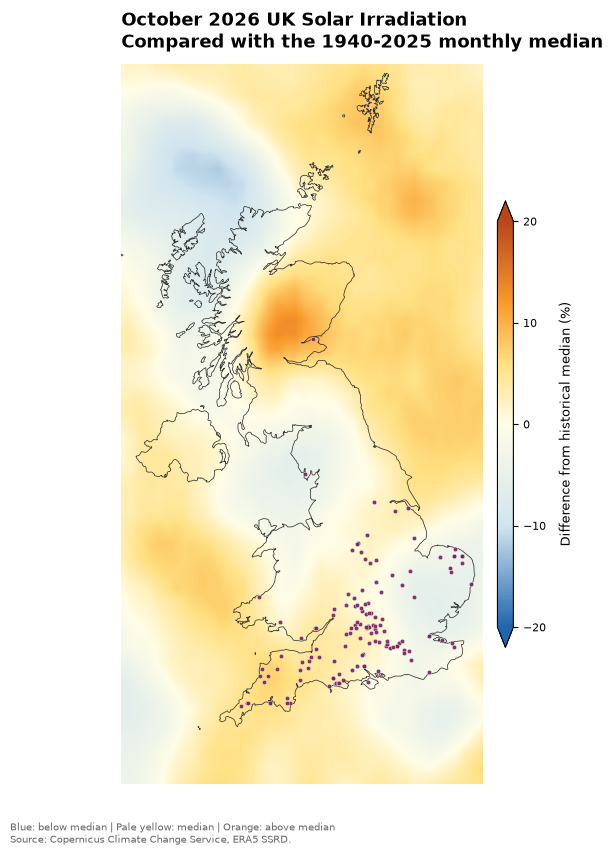

In [88]:
from matplotlib.colors import LinearSegmentedColormap

# Blue below median, pale yellow at zero, orange above median
comparison_cmap = LinearSegmentedColormap.from_list(
    "irradiation_comparison",
    [
        (0.00, "#2166ac"),
        (0.25, "#d1e5f0"),
        (0.50, "#fffde7"),
        (0.65, "#ffe082"),
        (0.80, "#f99a2c"),
        (1.00, "#b9471c"),
    ],
    N=256,
)
comparison_cmap.set_bad("#dddddd")  # I tried to make the sea a different colour but its not quite working and becomes blocky. A future visual improvement for the future perhaps instead

fig, ax = plt.subplots(figsize=(7.2, 9))

image = percentage_difference.transpose(
    "latitude", "longitude"
).plot.imshow(
    ax=ax,
    x="longitude",
    y="latitude",
    cmap=comparison_cmap,
    vmin=-20,
    vmax=20,
    interpolation="bilinear",
    add_colorbar=False,
    add_labels=False,
)

# Overlay the existing UK boundaries in longitude/latitude
uk_boundary.to_crs("EPSG:4326").boundary.plot(
    ax=ax,
    color="#333333",
    linewidth=0.55,
)

ax.scatter(
    sites["longitude"],
    sites["latitude"],
    s=10,
    color="#7a1f5c",
    edgecolor="white",
    linewidth=0.3,
    alpha=0.9,
    zorder=5,
)

ax.set_xlim(UK_BOUNDS["west"], UK_BOUNDS["east"])
ax.set_ylim(UK_BOUNDS["south"], UK_BOUNDS["north"])

ax.set_xlabel("")
ax.set_ylabel("")
ax.set_xticks([])
ax.set_yticks([])

for spine in ax.spines.values():
    spine.set_visible(False)

month_label = actual_month_name = (
    selected_month.valid_time.dt.strftime("%B %Y").values[0]
)

ax.set_title(
    f"{month_label} UK Solar Irradiation\n"
    f"Compared with the {BASELINE_START}-{BASELINE_END} monthly median",
    fontsize=13,
    fontweight="semibold",
    loc="left",
    pad=12,
)

colourbar = fig.colorbar(
    image,
    ax=ax,
    shrink=0.62,
    aspect=28,
    pad=0.025,
    ticks=[-20, -10, 0, 10, 20],
    extend="both",
)

colourbar.set_label(
    "Difference from historical median (%)",
    fontsize=9,
    labelpad=9,
)
colourbar.ax.tick_params(labelsize=8)

fig.text(
    0.08,
    0.035,
    "Blue: below median | Pale yellow: median | Orange: above median\n"
    "Source: Copernicus Climate Change Service, ERA5 SSRD.",
    fontsize=7,
    color="#666666",
)

fig.subplots_adjust(
    left=0.06,
    right=0.88,
    top=0.90,
    bottom=0.10,
)

plt.show()
 

In [64]:
#checking actual ranges
print(
    f"Lowest difference: "
    f"{percentage_difference.min(skipna=True).item():.1f}%"
)

print(
    f"Highest difference: "
    f"{percentage_difference.max(skipna=True).item():.1f}%"
)

Lowest difference: -12.4%
Highest difference: 29.6%
